# 01 — Exploratory Data Analysis

**Goal:** understand the raw dataset before any cleaning.  
All timestamps in this notebook are kept in **UTC** (as they arrive from the CSV).  
Timezone conversion happens in `02_cleaning.ipynb`.

## Key dataset facts (discovered from the real data)

- Columns: `oblast`, `raion`, `hromada`, `level`, `started_at`, `finished_at`, `source`
- The `level` column has three values: `'oblast'`, `'raion'`, `'hromada'`
- **One alarm event generates multiple rows** — one per administrative level.  
  Counting rows without filtering `level` triple-counts the same alert.
- There is **no `naive` column** in the official dataset — most end times are real.
- 25 unique oblasts, data from 2022-03-15 to present.

Plots:
1. `level` distribution
2. Daily alarm count nationwide (`level='oblast'` only, raw UTC)
3. Total alarms per oblast
4. Alarms by hour of day — UTC vs Kyiv time
5. Alarms by day of week
6. Heatmap: oblast × month

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Works whether VS Code kernel starts from project root or notebooks/
_candidates = [Path('../data/ukraine_alarms.csv'), Path('data/ukraine_alarms.csv')]
DATA_PATH = next(p for p in _candidates if p.exists())

## 1. Load & basic inspection

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape}')
df.head(10)

Shape: (272699, 7)


,oblast,raion,hromada,level,started_at,finished_at,source
0,Vinnytska oblast,NaN,NaN,oblast,2022-03-15 16:10:34+00:00,2022-03-15 16:50:07+00:00,official
1,Zhytomyrska oblast,NaN,NaN,oblast,2022-03-15 16:11:25+00:00,2022-03-15 16:54:23+00:00,official
2,Cherkaska oblast,Umanskyi raion,Umanska terytorialna hromada,hromada,2022-03-15 16:11:50+00:00,2022-03-15 16:54:47+00:00,official
3,Mykolaivska oblast,Pervomaiskyi raion,m. Pervomaisk ta Pervomaiska terytorialna hromada,hromada,2022-03-15 16:14:46+00:00,2022-03-15 16:57:08+00:00,official
4,Kirovohradska oblast,NaN,NaN,oblast,2022-03-15 16:15:11+00:00,2022-03-15 16:54:52+00:00,official
5,Khmelnytska oblast,Khmelnytskyi raion,m. Starokostiantyniv ta Starokostiantynivska t...,hromada,2022-03-15 16:16:00+00:00,2022-03-15 17:21:04+00:00,official
6,Kyivska oblast,Bilotserkivskyi raion,Skvyrska terytorialna hromada,hromada,2022-03-15 16:17:20+00:00,2022-03-15 16:55:55+00:00,official
7,Ivano-Frankivska oblast,NaN,NaN,oblast,2022-03-15 16:17:28+00:00,2022-03-15 17:14:18+00:00,official
8,Lvivska oblast,NaN,NaN,oblast,2022-03-15 16:17:29+00:00,2022-03-15 17:16:23+00:00,official
9,Rivnenska oblast,NaN,NaN,oblast,2022-03-15 16:18:35+00:00,2022-03-15 17:13:47+00:00,official


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 272699 entries, 0 to 272698
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   oblast       272699 non-null  str  
 1   raion        142646 non-null  str  
 2   hromada      35298 non-null   str  
 3   level        272699 non-null  str  
 4   started_at   272699 non-null  str  
 5   finished_at  272699 non-null  str  
 6   source       272699 non-null  str  
dtypes: str(7)
memory usage: 14.6 MB


In [4]:
# Parse as UTC-aware datetimes
df['started_at']  = pd.to_datetime(df['started_at'],  utc=True)
df['finished_at'] = pd.to_datetime(df['finished_at'], utc=True)

print(f"Date range: {df['started_at'].min().date()}  →  {df['started_at'].max().date()}")
print(f"Oblasts   : {df['oblast'].nunique()} unique")
print()
print(df.isnull().sum())

Date range: 2022-03-15  →  2026-06-22
Oblasts   : 25 unique

oblast              0
raion          130053
hromada        237401
level               0
started_at          0
finished_at         0
source              0
dtype: int64


## 2. Level distribution — why it matters

The `level` column tells us at which administrative level the alert was declared.  
A single alarm event can produce **one `'oblast'` row + several `'raion'` rows + several `'hromada'` rows** for the same timestamp.  
All analysis that counts "alarms" must first filter to one level to avoid triple-counting.

In [5]:
level_counts = df['level'].value_counts()
print(level_counts)
print(f"\nTotal rows: {len(df):,}")
print(f"If we filter level='oblast': {level_counts['oblast']:,} rows")
print(f"Ratio (all / oblast-only):  {len(df)/level_counts['oblast']:.2f}x")

level
oblast     130053
raion      107348
hromada     35298
Name: count, dtype: int64

Total rows: 272,699
If we filter level='oblast': 130,053 rows
Ratio (all / oblast-only):  2.10x


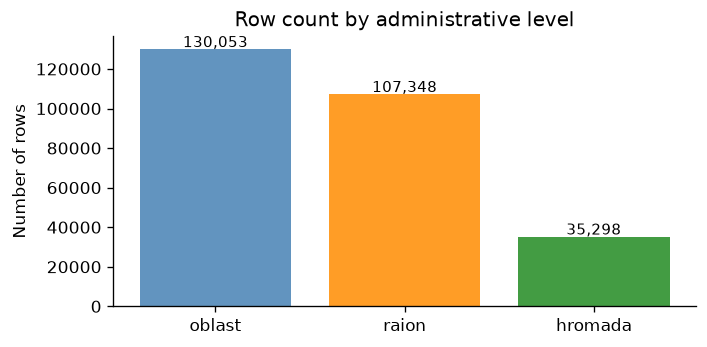

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(level_counts.index, level_counts.values, color=['steelblue','darkorange','forestgreen'], alpha=0.85)
ax.set_ylabel('Number of rows')
ax.set_title('Row count by administrative level', fontsize=12)
for i, v in enumerate(level_counts.values):
    ax.text(i, v + 1000, f'{v:,}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

## 3. Filter to oblast level only

For all remaining analysis we work with **`level='oblast'`** only.  
This gives us one row per oblast per alarm event — independent, comparable records.

In [7]:
dfo = df[df['level'] == 'oblast'].copy()
print(f'Oblast-level rows: {len(dfo):,}')
dfo.head(5)

Oblast-level rows: 130,053


,oblast,raion,hromada,level,started_at,finished_at,source
0,Vinnytska oblast,NaN,NaN,oblast,2022-03-15 16:10:34+00:00,2022-03-15 16:50:07+00:00,official
1,Zhytomyrska oblast,NaN,NaN,oblast,2022-03-15 16:11:25+00:00,2022-03-15 16:54:23+00:00,official
4,Kirovohradska oblast,NaN,NaN,oblast,2022-03-15 16:15:11+00:00,2022-03-15 16:54:52+00:00,official
7,Ivano-Frankivska oblast,NaN,NaN,oblast,2022-03-15 16:17:28+00:00,2022-03-15 17:14:18+00:00,official
8,Lvivska oblast,NaN,NaN,oblast,2022-03-15 16:17:29+00:00,2022-03-15 17:16:23+00:00,official


## Plot 1: Daily alarm count nationwide (UTC, oblast-level)

We group by calendar date in UTC. The day boundary sits at 22:00–23:00 Kyiv time —  
a late-evening alarm may end up counted on the wrong local day. Timezone fix happens in notebook 02.

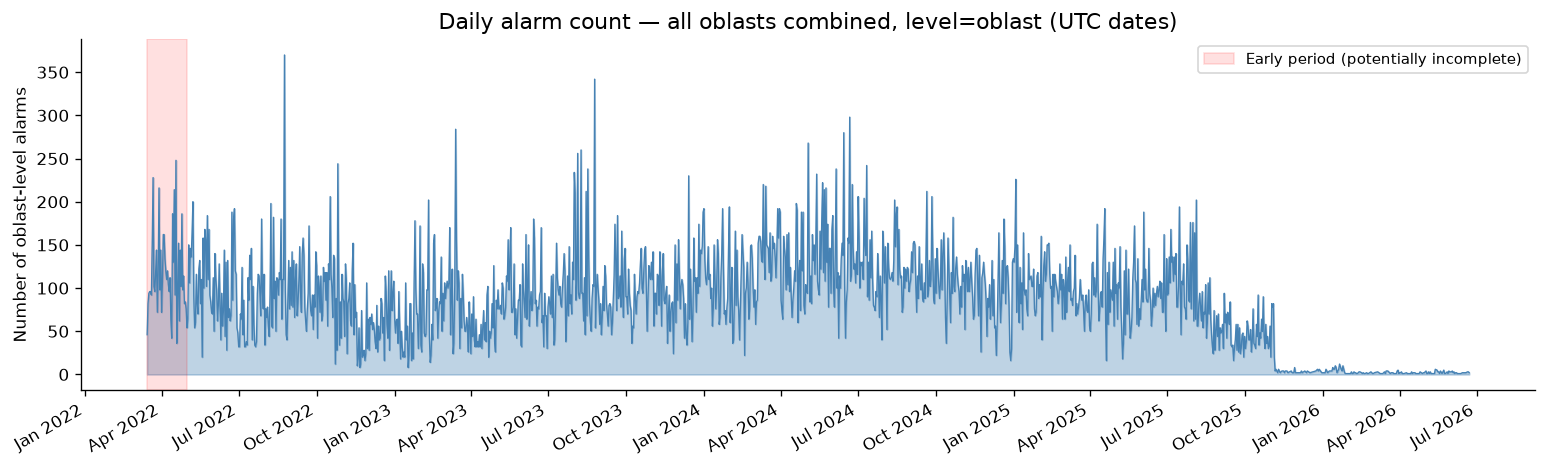

In [8]:
daily_utc = dfo.groupby(dfo['started_at'].dt.date).size().rename('n_alarms')
daily_utc.index = pd.to_datetime(daily_utc.index)

fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(daily_utc.index, daily_utc.values, alpha=0.35, color='steelblue')
ax.plot(daily_utc.index, daily_utc.values, linewidth=0.8, color='steelblue')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=30, ha='right')
ax.set_title('Daily alarm count — all oblasts combined, level=oblast (UTC dates)', fontsize=13)
ax.set_ylabel('Number of oblast-level alarms')
# Mark the early sparse period
ax.axvspan(pd.Timestamp('2022-03-15'), pd.Timestamp('2022-05-01'),
           alpha=0.12, color='red', label='Early period (potentially incomplete)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Plot 2: Total alarms per oblast

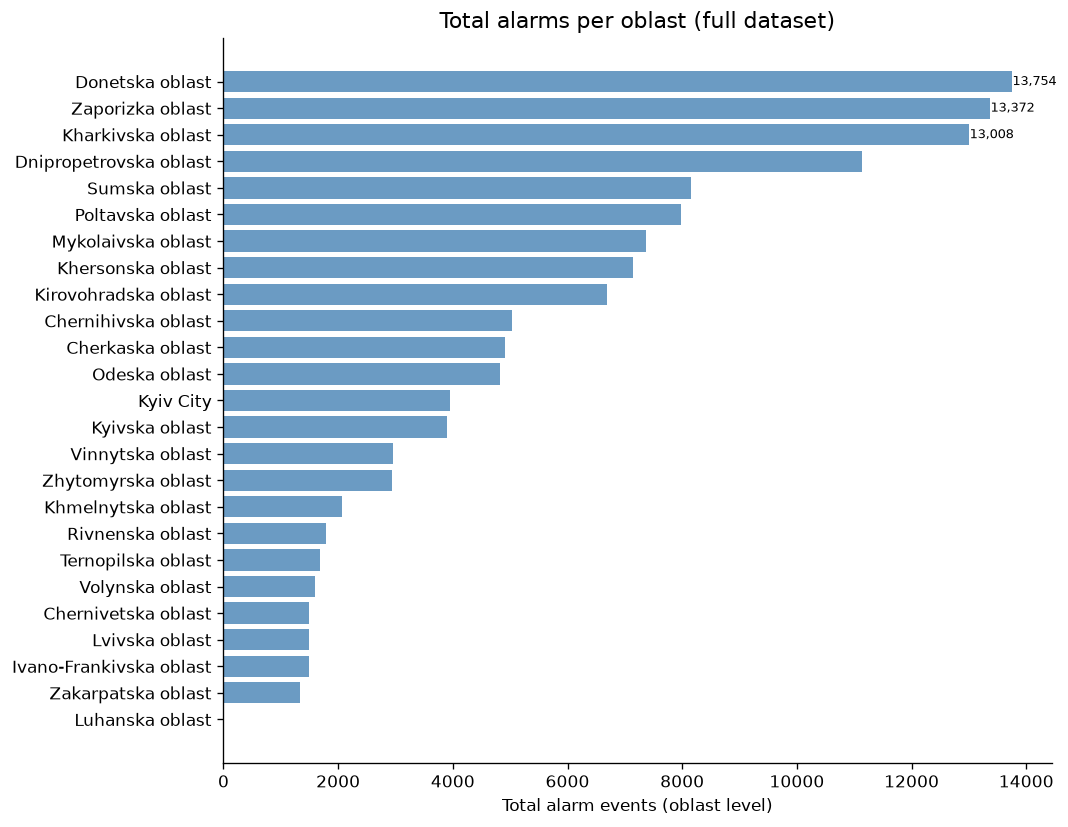

In [9]:
oblast_counts = dfo['oblast'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(oblast_counts.index, oblast_counts.values, color='steelblue', alpha=0.8)
ax.set_xlabel('Total alarm events (oblast level)')
ax.set_title('Total alarms per oblast (full dataset)', fontsize=13)
for bar, val in zip(bars[-3:], oblast_counts.values[-3:]):
    ax.text(val + 5, bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontsize=8)
plt.tight_layout()
plt.show()

## Plot 3: Alarms by hour of day — UTC vs Kyiv time

**Key point:** Kyiv is UTC+2 winter / UTC+3 summer. Grouping by UTC hour shifts the peak by 2–3 slots compared to local time.  
This is the clearest demonstration of why timezone conversion is mandatory.

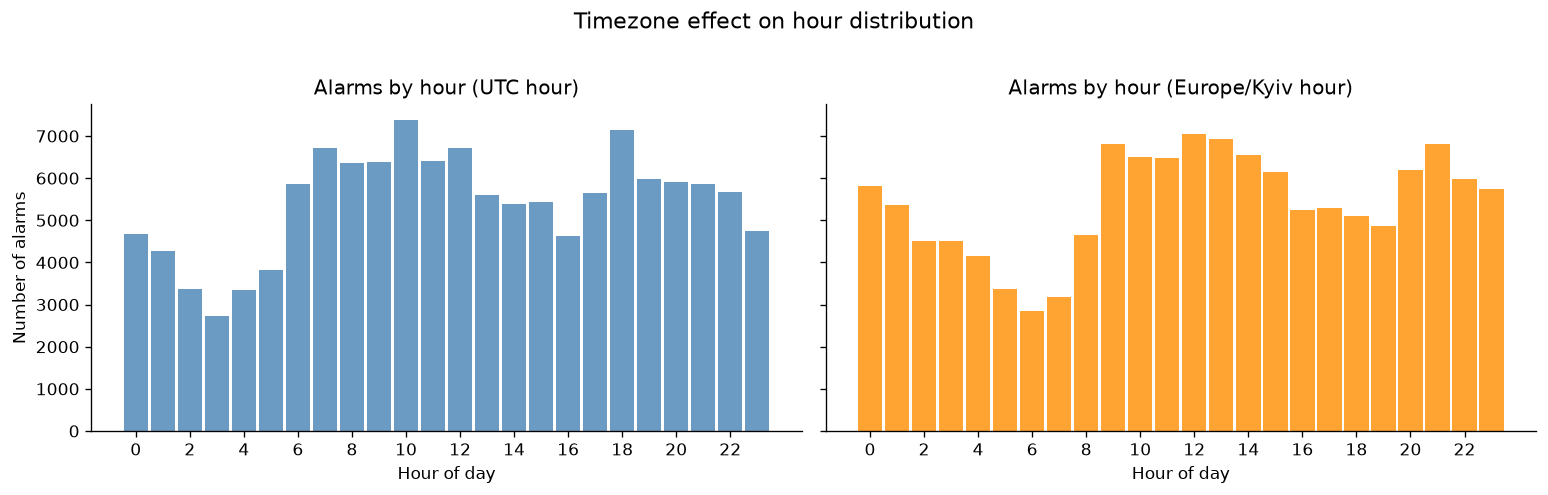

UTC peak hour  : 10:00
Kyiv peak hour : 12:00
Shift          : 2 hours


In [10]:
started_kyiv = dfo['started_at'].dt.tz_convert('Europe/Kyiv')

hour_utc  = dfo['started_at'].dt.hour.value_counts().sort_index()
hour_kyiv = started_kyiv.dt.hour.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, series, label, color in zip(
    axes,
    [hour_utc, hour_kyiv],
    ['UTC hour', 'Europe/Kyiv hour'],
    ['steelblue', 'darkorange']
):
    ax.bar(series.index, series.values, color=color, alpha=0.8, width=0.9)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel('Hour of day')
    ax.set_title(f'Alarms by hour ({label})', fontsize=12)
axes[0].set_ylabel('Number of alarms')
fig.suptitle('Timezone effect on hour distribution', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
print(f"UTC peak hour  : {hour_utc.idxmax():02d}:00")
print(f"Kyiv peak hour : {hour_kyiv.idxmax():02d}:00")
print(f"Shift          : {hour_kyiv.idxmax() - hour_utc.idxmax()} hours")

## Plot 4: Alarms by day of week (Kyiv time)

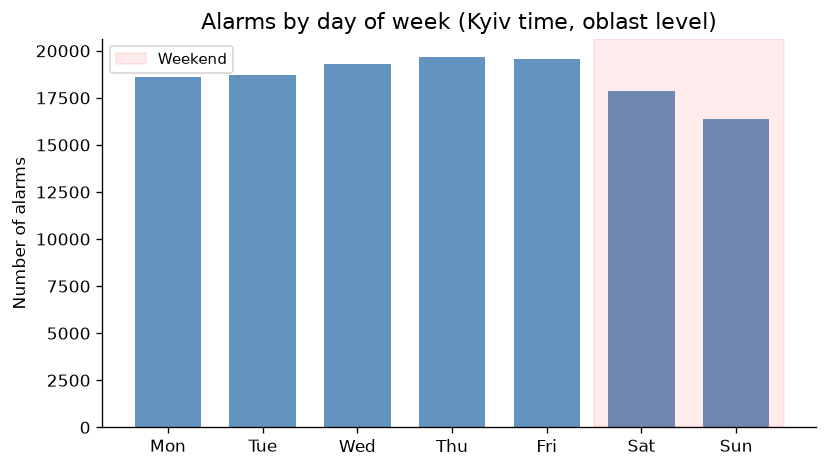

In [11]:
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow = started_kyiv.dt.dayofweek.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(dow.index, dow.values, color='steelblue', alpha=0.85, width=0.7)
ax.set_xticks(range(7))
ax.set_xticklabels(day_names)
ax.set_ylabel('Number of alarms')
ax.set_title('Alarms by day of week (Kyiv time, oblast level)', fontsize=13)
ax.axvspan(4.5, 6.5, alpha=0.08, color='red', label='Weekend')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Plot 5: Heatmap — alarms per oblast per month

Reveals geographic patterns and any months with unusually low coverage (potential data gaps).

/tmp/ipykernel_84002/1004076804.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  dfo['month'] = started_kyiv.dt.to_period('M').astype(str)


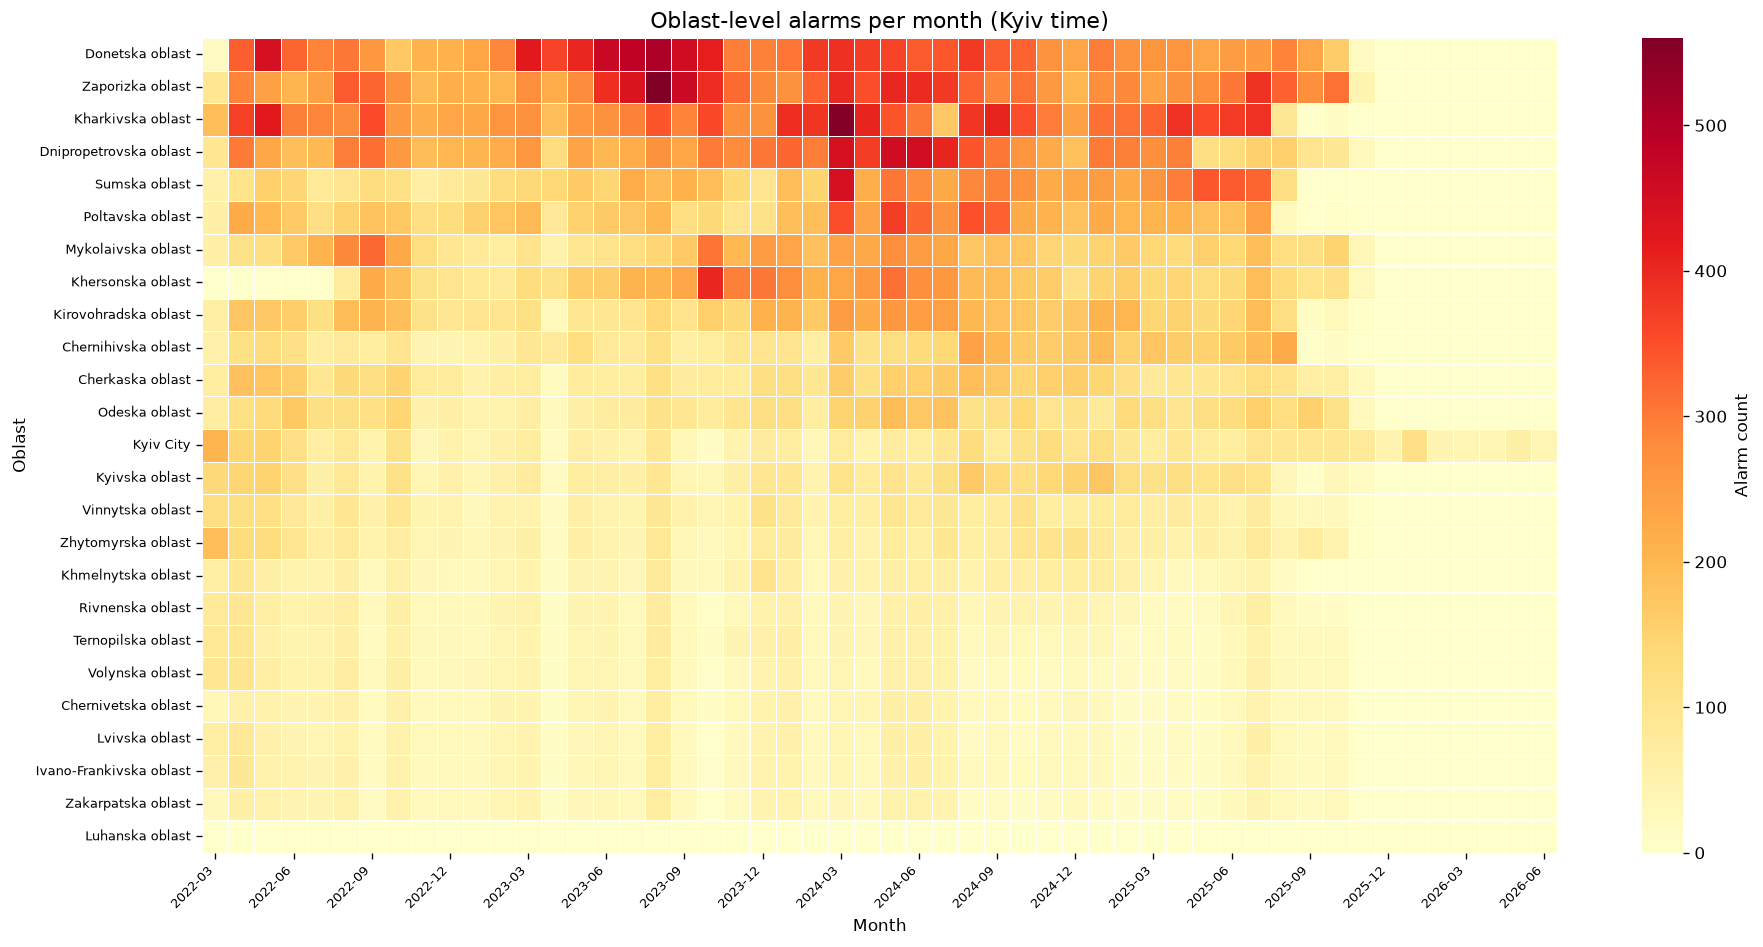

In [12]:
dfo = dfo.copy()
dfo['month'] = started_kyiv.dt.to_period('M').astype(str)
heatmap_data = dfo.groupby(['oblast', 'month']).size().unstack(fill_value=0)
heatmap_data = heatmap_data.loc[heatmap_data.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(16, 8))
sns.heatmap(
    heatmap_data, ax=ax, cmap='YlOrRd', linewidths=0.3,
    cbar_kws={'label': 'Alarm count'},
    xticklabels=3
)
ax.set_title('Oblast-level alarms per month (Kyiv time)', fontsize=13)
ax.set_xlabel('Month')
ax.set_ylabel('Oblast')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## Summary

| Observation | Detail |
|-------------|--------|
| Granularity trap | All rows ÷ oblast-only rows ≈ 2.1× — must filter before counting |
| Timezone shift | UTC vs Kyiv peak hour differs by 2–3 h — convert before day groupby |
| Geographic pattern | Frontline oblasts lead the heatmap |
| Early period | March 2022 may be incomplete — check in cleaning |

→ Next: `02_cleaning.ipynb` for timezone fix, duration outliers, and building `daily_counts.csv`.